## Домашка 4

#### *«Вы видите, но не наблюдаете.» — Шерлок*

Эта домашка про мониторинг метрик и детекцию аномалий. За неё можно получить максимум 12 баллов.

**Дедлайны**   
Жесткий дедлайн: 18.10.2026 23:59 по МСК.

После жесткого дедлайна работы не принимаются.

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета.
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_4). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3.

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_4_data.zip)

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import t
from statsmodels.tsa.seasonal import STL
import math

### Warm up

#### 1. Сопоставьте метод детекции аномалий с контекстом применения — 2 балла

a) Онлайн-мониторинг   
b) Батч-анализ по историческим данным  

1. Правило 3σ.
2. Generalized ESD
3. Grubbs test
4. CUMSUM
5. EWMA
6. STL-разложение + Generalized ESD

1 - A

2 - B

3 - B

4 - A

5 - A

6 - B

### Case Study. Система мониторинга метрик для Ecom-приложения 🥪

**Легенда**  
Вы работаете продуктовым аналитиком в ecom-приложении доставки FMCG-товаров. Компания — развивающийся стартап, в котором еще не выстроена система мониторинга метрик.   

Вам поручили провести исследование подходов к детекции аномалий на исторических данных и выбрать методологии, которые будет применять ваша компания для онлайн-мониторинга и ретроспективного анализа.

In [ ]:
df = pd.read_csv('hw_4_fmcg.csv')

In [ ]:
df['date'] = pd.to_datetime(df['date'])

In [ ]:
df.head()

,date,items_sold,gmv,avg_item_price
0,2023-01-01,2907,14944.41,5.140836
1,2023-01-02,3030,16065.13,5.302023
2,2023-01-03,3070,17170.30,5.592932
3,2023-01-04,2708,14367.19,5.305462
4,2023-01-05,3177,16918.53,5.325316


Описание данных:

- date — дата, на которую агрегированы данные
- items_sold — число проданных в день товаров
- gmv – GMV проданных в день товаров
- avg_item_price — средняя цена проданных в день товаров

#### 2. Правило 3σ — 2 балла

1) Реализуйте правило 3σ для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты.

2) Постройте графики: метрика + границы контроля + выделенные аномалии.

*Советую обернуть правило для расчета 3σ в функцию, она пригодится на следующем шаге.*

**Внимание: Тут и в дальнейшем для визуализации и ответа на тестовые вопросы формы используйте только данные ЗА МАЙ.**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = df.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
for c in ["gmv", "items_sold", "avg_item_price"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

In [ ]:
def rule_3sigma(series: pd.Series, window: int = 28, k: float = 3.0) -> pd.DataFrame:
    s = series.astype(float)
    rolled = s.shift(1).rolling(window=window, min_periods=window)
    mu = rolled.mean()
    sd = rolled.std(ddof=1)
    lower = mu - k * sd
    upper = mu + k * sd
    is_anom = ((s < lower) | (s > upper)) & mu.notna()
    return pd.DataFrame({
        "value": s, "mean": mu, "std": sd,
        "lower": lower, "upper": upper, "is_anomaly": is_anom
    })

In [ ]:
print(df["date"].min(), df["date"].max())        # попадает ли май в диапазон?
print(df["date"].dt.year.unique())               # какой год? (2023/2024/…)
print(df[["gmv","items_sold","avg_item_price"]].isna().sum())
print(df[["gmv","items_sold","avg_item_price"]].describe())

2023-01-01 00:00:00 2023-12-31 00:00:00
[2023]
gmv               0
items_sold        0
avg_item_price    0
dtype: int64
                gmv   items_sold  avg_item_price
count    365.000000   365.000000      365.000000
mean   23113.023452  4397.282192        5.257583
std     3876.788951   733.908500        0.167018
min    13730.770000  2708.000000        4.729855
25%    20358.540000  3860.000000        5.153945
50%    22827.830000  4278.000000        5.252604
75%    26258.790000  5020.000000        5.370699
max    31504.140000  6018.000000        5.849209



=== gmv ===
точек в мае: 31, NaN границ: 0, аномалий: 1
  2023-05-27  value=3.041e+04  [2.174e+04; 2.996e+04]  (выше)


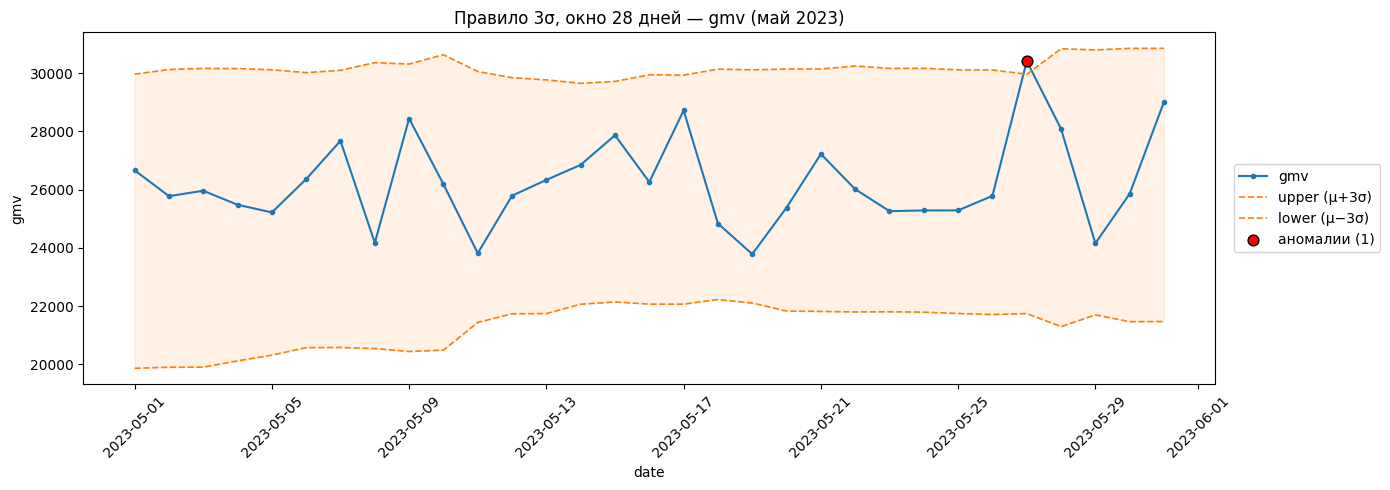


=== items_sold ===
точек в мае: 31, NaN границ: 0, аномалий: 1
  2023-05-27  value=5747  [4212; 5658]  (выше)


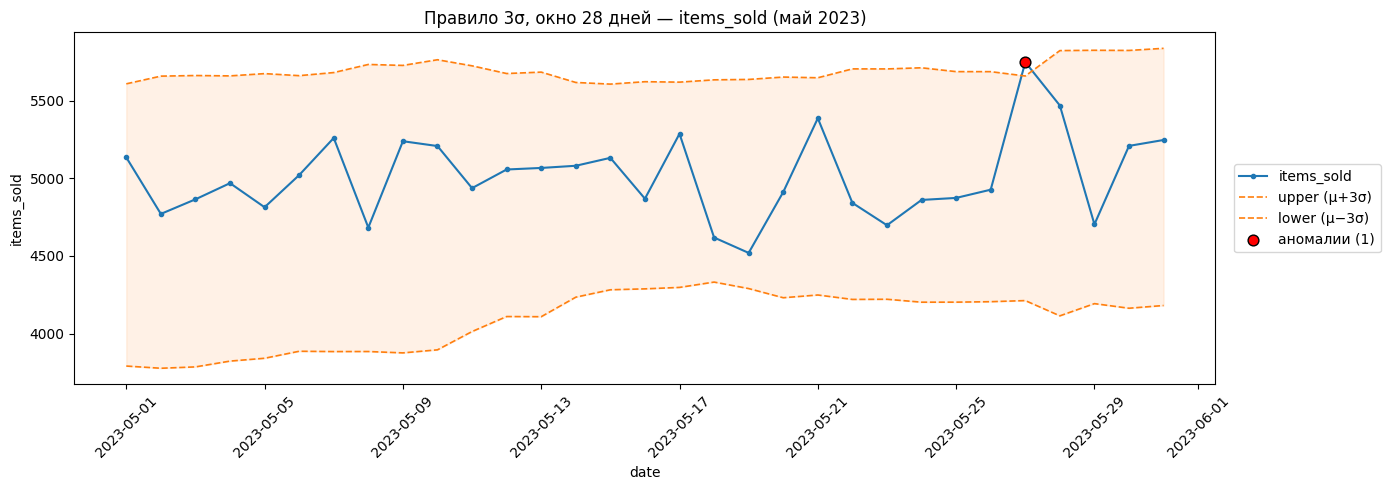


=== avg_item_price ===
точек в мае: 31, NaN границ: 0, аномалий: 1
  2023-05-11  value=4.824  [4.86; 5.723]  (ниже)


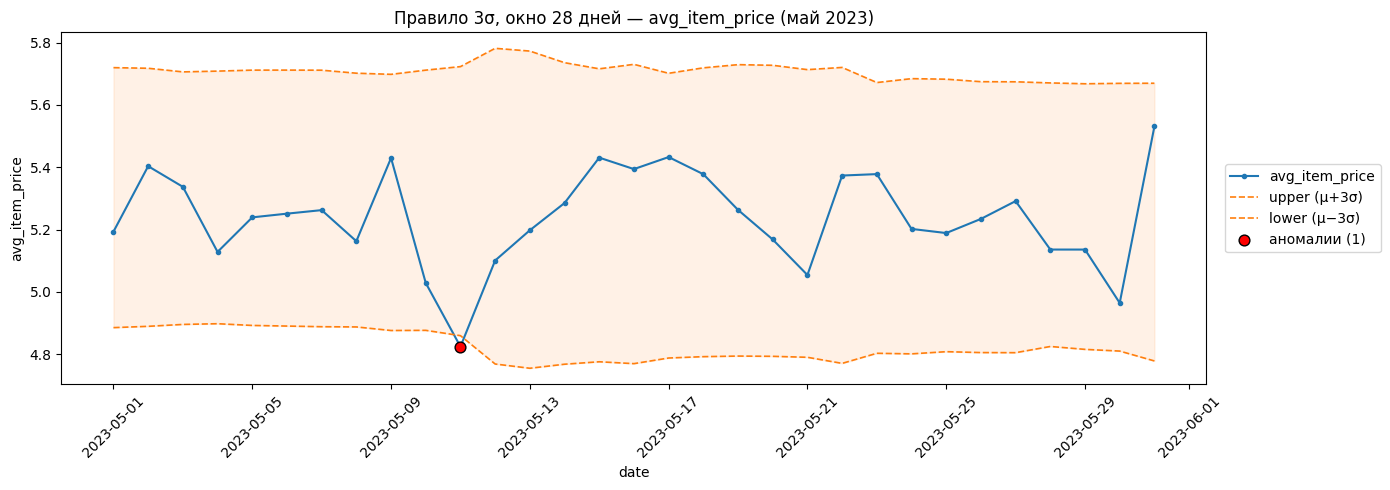

In [ ]:
s_all = df.set_index("date")[["gmv", "items_sold", "avg_item_price"]]
MAY_START, MAY_END = "2023-05-01", "2023-05-31"

results = {}
for m in ["gmv", "items_sold", "avg_item_price"]:
    r = rule_3sigma(s_all[m], window=28, k=3.0)
    results[m] = r

    d = r.loc[MAY_START:MAY_END]
    print(f"\n=== {m} ===")
    print(f"точек в мае: {len(d)}, NaN границ: {d['lower'].isna().sum()}, "
          f"аномалий: {int(d['is_anomaly'].sum())}")
    if d["is_anomaly"].any():
        for dt, row in d[d["is_anomaly"]].iterrows():
            side = "выше" if row["value"] > row["upper"] else "ниже"
            print(f"  {dt.date()}  value={row['value']:.4g}  "
                  f"[{row['lower']:.4g}; {row['upper']:.4g}]  ({side})")
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(d.index, d["value"], color="C0", lw=1.5, marker="o", ms=3, label=m)
    ax.plot(d.index, d["upper"], "--", color="C1", lw=1.2, label="upper (μ+3σ)")
    ax.plot(d.index, d["lower"], "--", color="C1", lw=1.2, label="lower (μ−3σ)")
    ax.fill_between(d.index, d["lower"], d["upper"], color="C1", alpha=0.10)

    anom = d[d["is_anomaly"]]
    if len(anom):
        ax.scatter(anom.index, anom["value"], color="red", s=60,
                   zorder=5, edgecolors="black", label=f"аномалии ({len(anom)})")

    ax.set_title(f"Правило 3σ, окно 28 дней — {m} (май 2023)")
    ax.set_xlabel("date"); ax.set_ylabel(m)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=True)
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

#### 3. Дельта-ряды — 2 балла

1) Рассчитайте дельты значений текущего дня с предыдущим для каждой метрики, затем примените к полученным дельтам правило 3σ:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты.

2) Постройте графики: дельты метрики + границы контроля + выделенные аномалии.

In [ ]:
s_all = df.set_index("date")[["gmv", "items_sold", "avg_item_price"]]

delta_results = {}
for m in ["gmv", "items_sold", "avg_item_price"]:
    delta = s_all[m].diff()                 # delta[t] = value[t] - value[t-1]
    r = rule_3sigma(delta, window=28, k=3.0)
    delta_results[m] = r



=== Δgmv (дельта) ===
точек в мае: 31, NaN границ: 0, аномалий: 0


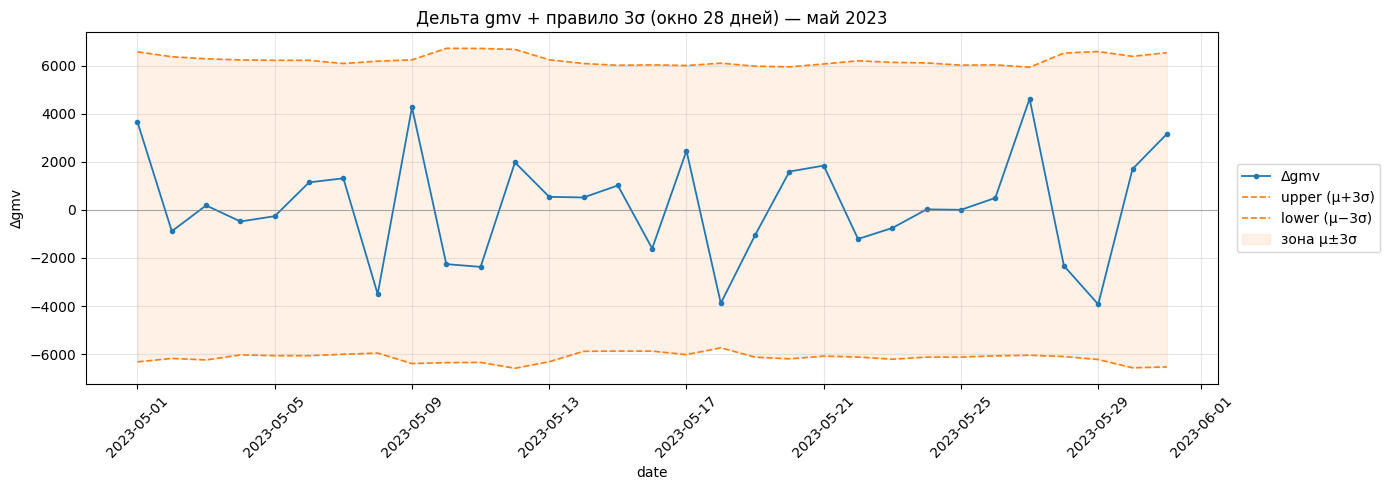


=== Δitems_sold (дельта) ===
точек в мае: 31, NaN границ: 0, аномалий: 0


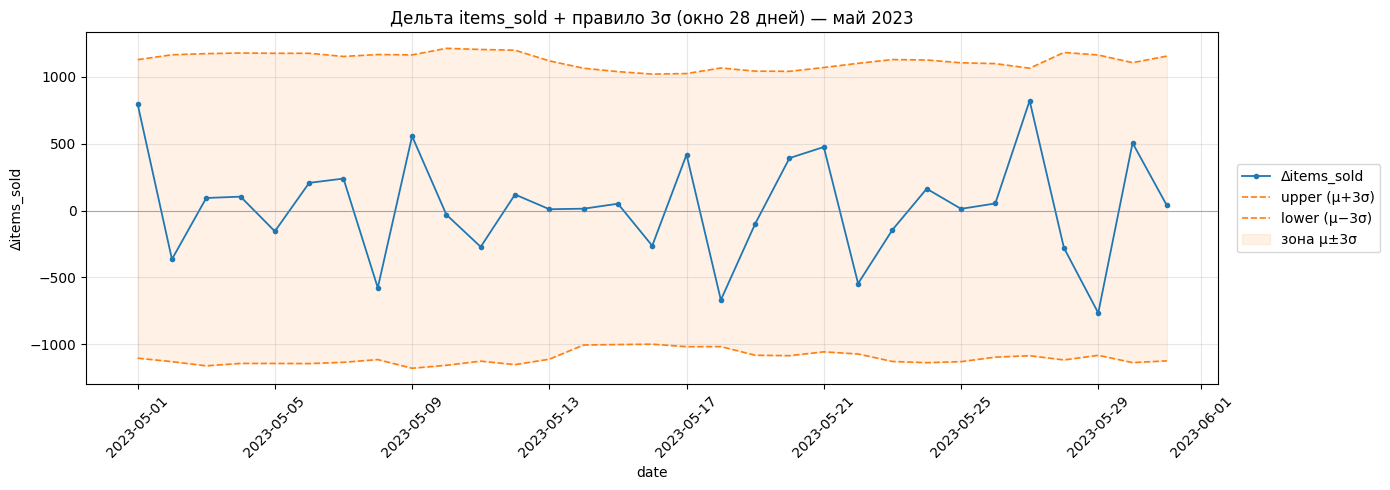


=== Δavg_item_price (дельта) ===
точек в мае: 31, NaN границ: 0, аномалий: 1
  2023-05-31  Δ=+0.5662  [-0.4934; 0.462]  (выше)


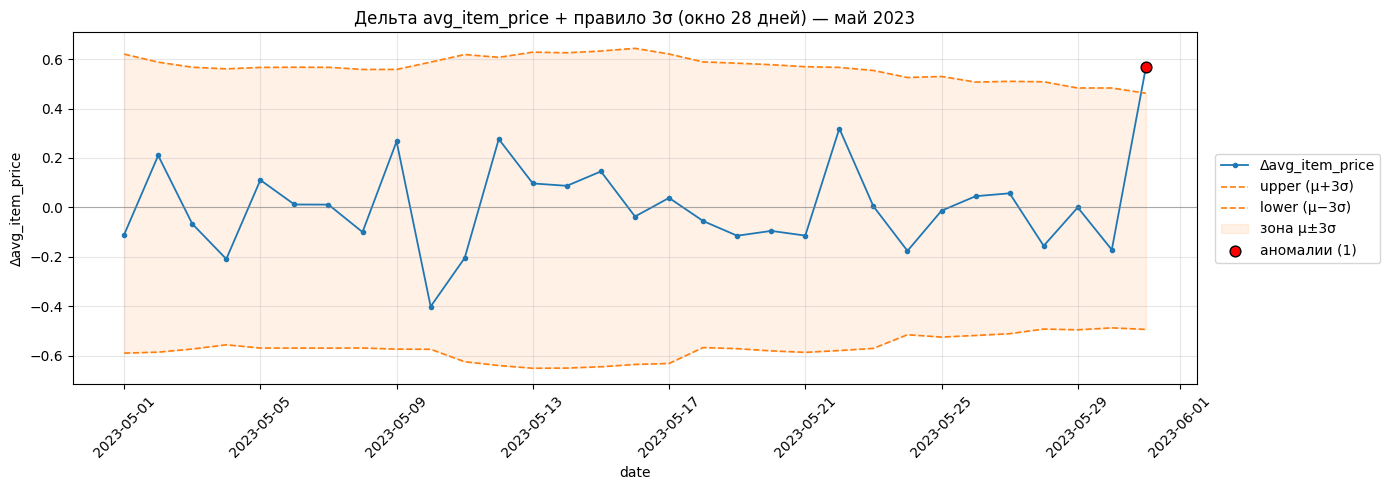

In [ ]:
MAY_START, MAY_END = "2023-05-01", "2023-05-31"

for m in ["gmv", "items_sold", "avg_item_price"]:
    r = delta_results[m]
    d = r.loc[MAY_START:MAY_END]

    print(f"\n=== Δ{m} (дельта) ===")
    print(f"точек в мае: {len(d)}, NaN границ: {d['lower'].isna().sum()}, "
          f"аномалий: {int(d['is_anomaly'].sum())}")
    if d["is_anomaly"].any():
        for dt, row in d[d["is_anomaly"]].iterrows():
            side = "выше" if row["value"] > row["upper"] else "ниже"
            print(f"  {dt.date()}  Δ={row['value']:+.4g}  "
                  f"[{row['lower']:.4g}; {row['upper']:.4g}]  ({side})")

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(d.index, d["value"], color="C0", lw=1.3, marker="o", ms=3,
            label=f"Δ{m}")
    ax.axhline(0, color="gray", lw=0.8, alpha=0.6)
    ax.plot(d.index, d["upper"], "--", color="C1", lw=1.2, label="upper (μ+3σ)")
    ax.plot(d.index, d["lower"], "--", color="C1", lw=1.2, label="lower (μ−3σ)")
    ax.fill_between(d.index, d["lower"], d["upper"], color="C1", alpha=0.10,
                    label="зона μ±3σ")

    anom = d[d["is_anomaly"]]
    if len(anom):
        ax.scatter(anom.index, anom["value"], color="red", s=60,
                   zorder=5, edgecolors="black",
                   label=f"аномалии ({len(anom)})")

    ax.set_title(f"Дельта {m} + правило 3σ (окно 28 дней) — май 2023")
    ax.set_xlabel("date"); ax.set_ylabel(f"Δ{m}")
    ax.grid(alpha=0.3)
    plt.xticks(rotation=45)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))  # легенда справа
    plt.tight_layout()
    plt.show()

#### 4. Generalized ESD — 2 балла

1) Реализуйте Generalized ESD. Обратите внимание, с какими данными работает метод — онлайн или батч? Учтите это в реализации.
2) Найдите аномалии для дельт каждой метрики ЗА МАЙ (используйте данные, полученные на прошлом шаге):
- gmv;
- items_sold;
- avg_item_price.
3) Сравните результаты с правилом 3σ на дельтах: разошлись ли методы?

*Советую обернуть Generalized ESD в функцию, она пригодится на следующем шаге.*

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

def generalized_esd(x, max_outliers=None, alpha=0.05):
    x = np.asarray(x, dtype=float)
    n = len(x)
    if n < 3:
        return np.array([], dtype=int), [], []

    if max_outliers is None:
        max_outliers = max(1, int(0.2 * n))
    max_outliers = min(max_outliers, n - 3)

    idx = np.arange(n)
    R = []
    lam = []

    for i in range(1, max_outliers + 1):
        m = len(idx)
        if m < 3:
            break
        xi = x[idx]
        mean_i = xi.mean()
        std_i = xi.std(ddof=1)
        if std_i == 0:
            break

        dev = np.abs(xi - mean_i) / std_i
        max_pos = np.argmax(dev)
        R_i = dev[max_pos]
        R.append(R_i)

        p = 1 - alpha / (2 * m)
        t = stats.t.ppf(p, m - 2)
        lam_i = (m - 1) * t / np.sqrt((m - 2 + t**2) * m)
        lam.append(lam_i)

        idx = np.delete(idx, max_pos)

    num_outliers = 0
    for i in range(len(R)):
        if R[i] > lam[i]:
            num_outliers = i + 1
        else:
            pass

    idx_work = np.arange(n)
    outlier_indices = []
    for i in range(num_outliers):
        xi = x[idx_work]
        mean_i = xi.mean()
        std_i = xi.std(ddof=1)
        if std_i == 0:
            break
        dev = np.abs(xi - mean_i) / std_i
        max_pos = np.argmax(dev)
        outlier_indices.append(idx_work[max_pos])
        idx_work = np.delete(idx_work, max_pos)

    return np.array(outlier_indices, dtype=int), R, lam


=== GESD на дельтах gmv (май, окно 28, α=0.05) ===
Аномалий: 0


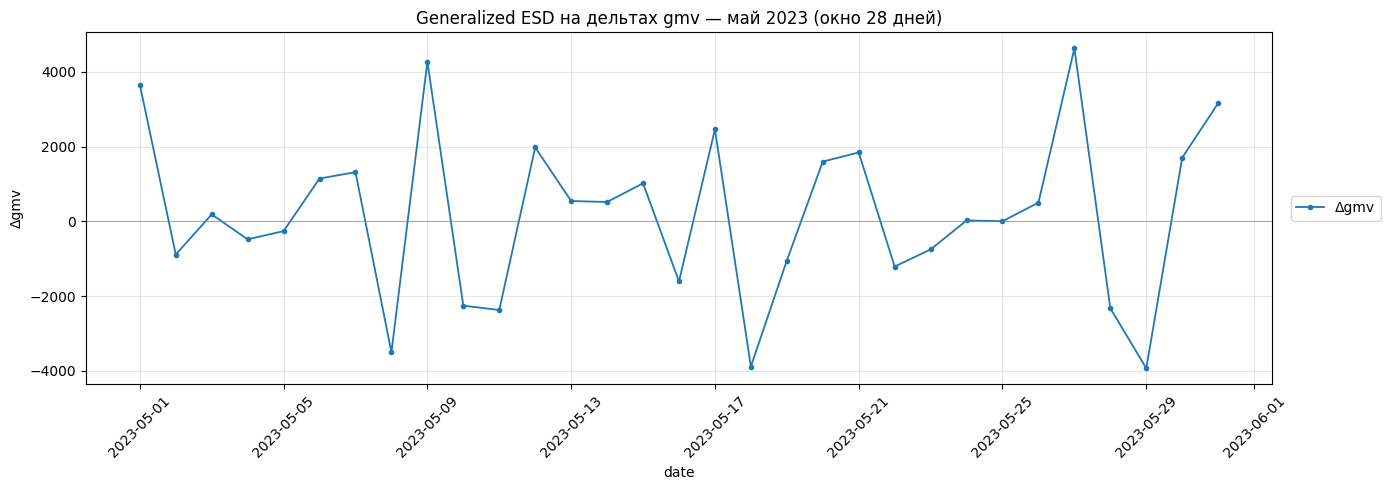


=== GESD на дельтах items_sold (май, окно 28, α=0.05) ===
Аномалий: 0


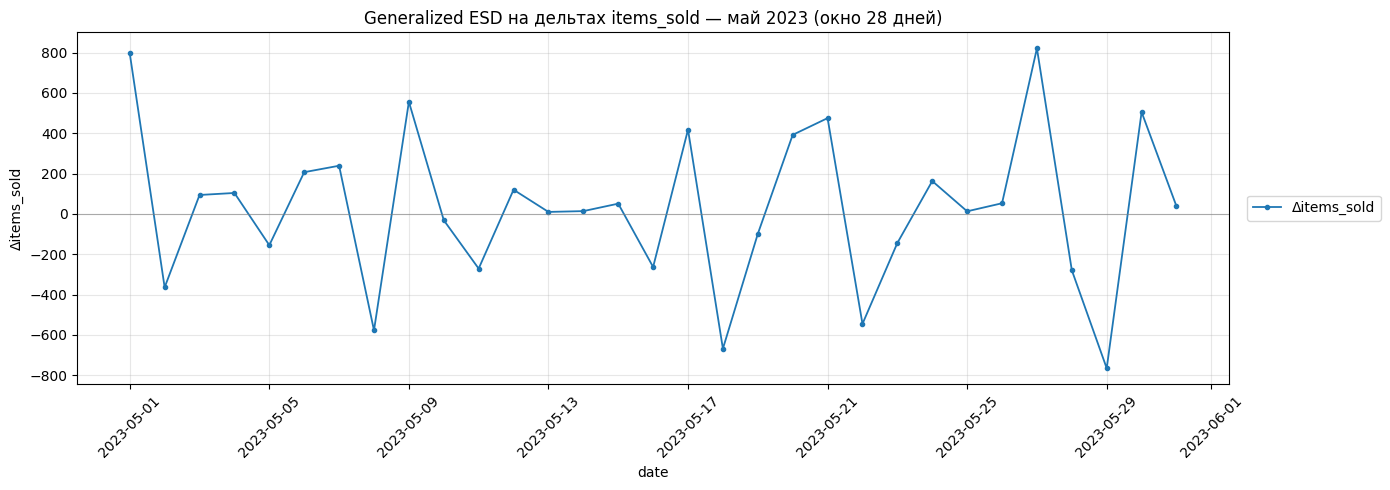


=== GESD на дельтах avg_item_price (май, окно 28, α=0.05) ===
Аномалий: 1
  2023-05-31  Δ=+0.5662


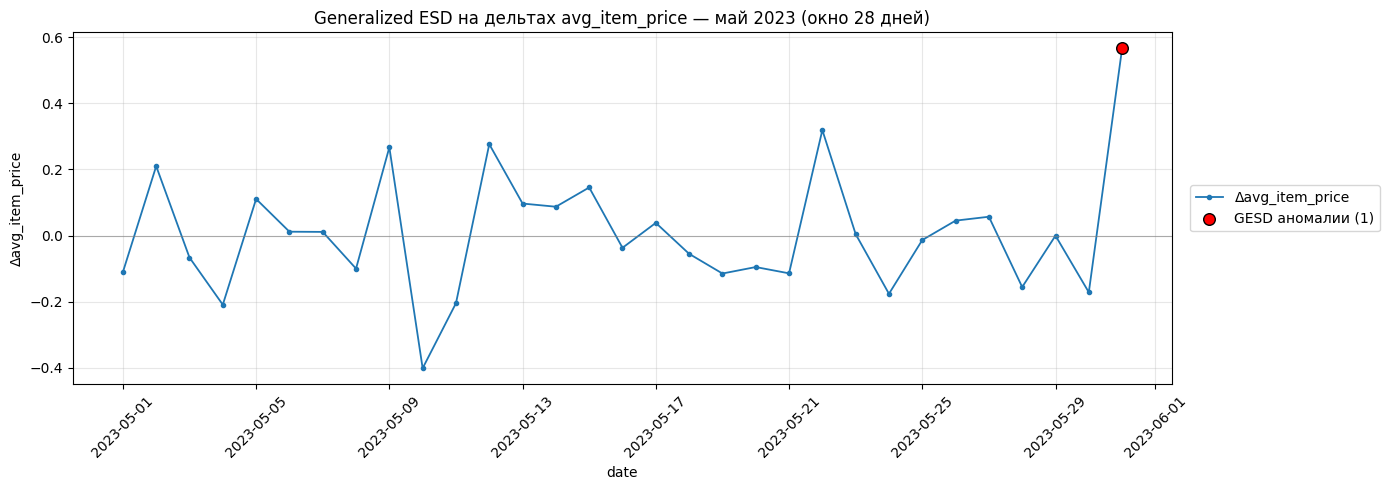

In [ ]:
MAY_START, MAY_END = "2023-05-01", "2023-05-31"
WINDOW = 28
ALPHA = 0.05

gesd_results = {}

for m in ["gmv", "items_sold", "avg_item_price"]:
    delta_series = s_all[m].diff().dropna()
    dates = delta_series.index
    anomalies = []
    for dt in dates[(dates >= MAY_START) & (dates <= MAY_END)]:
        pos = dates.get_loc(dt)
        if pos < WINDOW:
            continue
        window_vals = delta_series.iloc[pos - WINDOW: pos].values
        current_val = delta_series.iloc[pos]

        combined = np.append(window_vals, current_val)
        out_idx, R, lam = generalized_esd(combined, max_outliers=min(10, WINDOW // 2), alpha=ALPHA)

        if WINDOW in out_idx:
            anomalies.append(dt)

    gesd_results[m] = anomalies
    print(f"\n=== GESD на дельтах {m} (май, окно {WINDOW}, α={ALPHA}) ===")
    print(f"Аномалий: {len(anomalies)}")
    if anomalies:
        for dt in anomalies:
            print(f"  {dt.date()}  Δ={delta_series.loc[dt]:+.4g}")

    d_may = delta_series.loc[MAY_START:MAY_END]
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(d_may.index, d_may.values, color="C0", lw=1.3, marker="o", ms=3, label=f"Δ{m}")
    ax.axhline(0, color="gray", lw=0.8, alpha=0.6)

    if anomalies:
        y_anom = [delta_series.loc[dt] for dt in anomalies]
        ax.scatter(anomalies, y_anom, color="red", s=70, zorder=5,
                   edgecolors="black", label=f"GESD аномалии ({len(anomalies)})")

    ax.set_title(f"Generalized ESD на дельтах {m} — май 2023 (окно {WINDOW} дней)")
    ax.set_xlabel("date"); ax.set_ylabel(f"Δ{m}")
    ax.grid(alpha=0.3); plt.xticks(rotation=45)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout(); plt.show()

GESD — батч-метод, для сравнения с 3σ применён скользящим окном 28 дней. На дельтах за май 2023 оба метода дали идентичный результат: аномалия только 2023-05-31 по avg_item_price. Расхождений нет, поскольку в мае в дельтах отсутствуют множественные выбросы (эффект маскировки не проявляется). Различие GESD и 3σ ожидаемо проявляется на данных с 2+ выбросами в окне — на майских дельтах такого сценария нет

#### 6. EWMA — 2 балла

1) Реализуйте метод EWMA для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Сглаженная статистика считается рекуррентно с параметром $\lambda = 0.2$:

$$
z_t = \lambda x_t + (1-\lambda)\, z_{t-1}, \qquad z_0 = x_0,
$$

где $x_t$ — исходное дневное значение метрики. В pandas это делает [встроенная функция экспоненциального сглаживания](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html) — обратите внимание на параметр `adjust=False`, именно он дает рекуррентную форму выше.

Контрольные границы задаются как

$$
\mu_t \pm L\,\sigma_t \sqrt{\frac{\lambda}{2-\lambda}}, \qquad L = 3.
$$

Здесь $\mu_t$ и $\sigma_t$ — среднее и стандартное отклонение **исходного ряда $x_t$**, а не сглаженного $z_t$, посчитанные на скользящем окне 28 дней. Множитель $\sqrt{\lambda/(2-\lambda)}$ — асимптотическое приближение отношения дисперсии сглаженной статистики к дисперсии сырых наблюдений: он уже учитывает, что $z_t$ колеблется меньше, чем $x_t$, поэтому подставлять в формулу разброс самого $z_t$ нельзя — сжатие применится дважды, и коридор получится слишком узким.

Окно для $\mu_t$ и $\sigma_t$ должно заканчиваться на предыдущем дне (`.rolling(28).mean().shift(1)`), иначе текущее наблюдение попадёт в собственную оценку разброса и аномалия спрячет сама себя.

2) Постройте графики: сглаженная метрика + границы контроля + выделенные аномалии.
3) Напишите, какой из подходов вам больше всего понравился для онлайн-мониторинга, а какой — для ретроспективного анализа, и почему. Тут нет правильного ответа :)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def ewma_control(series: pd.Series, lam: float = 0.2, L: float = 3.0,
                 window: int = 28) -> pd.DataFrame:
    x = series.astype(float)
    z = x.ewm(alpha=lam, adjust=False).mean()

    rolled = x.rolling(window=window, min_periods=window).mean().shift(1)
    mu = rolled
    sd = x.rolling(window=window, min_periods=window).std(ddof=1).shift(1)

    factor = np.sqrt(lam / (2.0 - lam))

    lower = mu - L * sd * factor
    upper = mu + L * sd * factor

    is_anom = ((z < lower) | (z > upper)) & mu.notna()

    return pd.DataFrame({
        "x": x, "z": z, "mu": mu, "sigma": sd,
        "lower": lower, "upper": upper, "is_anomaly": is_anom
    })


=== EWMA: gmv (май 2023) ===
точек: 31, NaN границ: 0, аномалий: 0


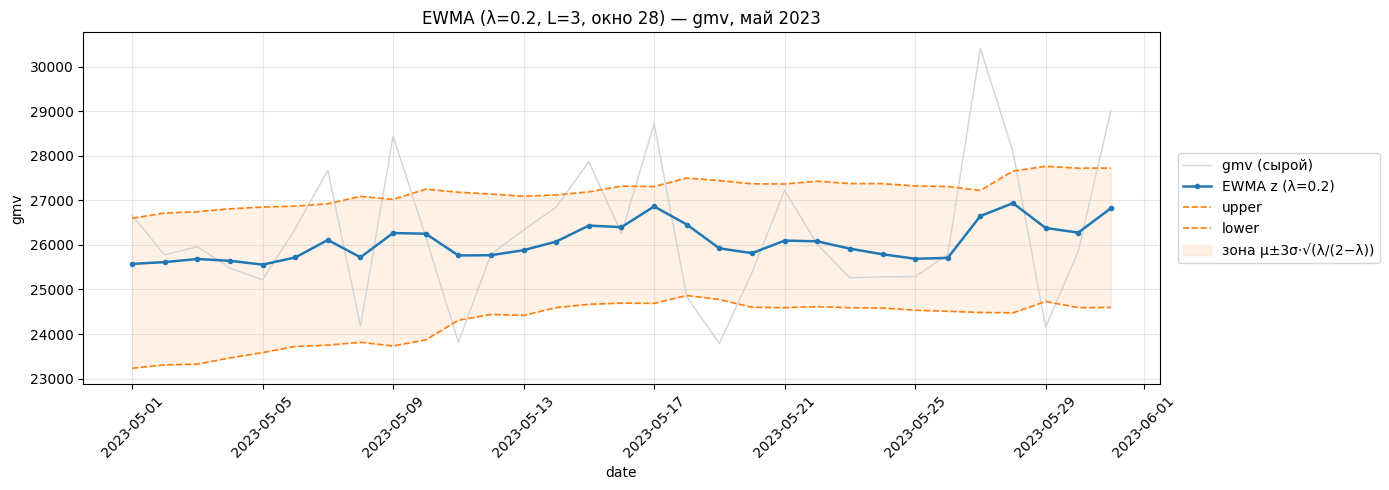


=== EWMA: items_sold (май 2023) ===
точек: 31, NaN границ: 0, аномалий: 0


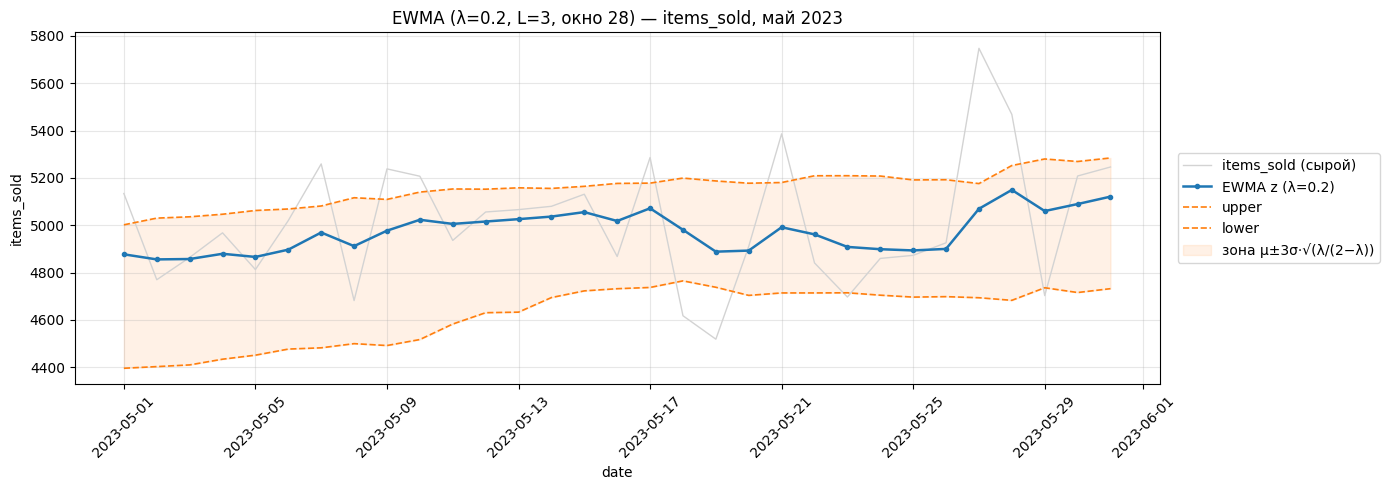


=== EWMA: avg_item_price (май 2023) ===
точек: 31, NaN границ: 0, аномалий: 1
  2023-05-11  z=5.146  x=4.824  [5.147; 5.435]  (ниже)


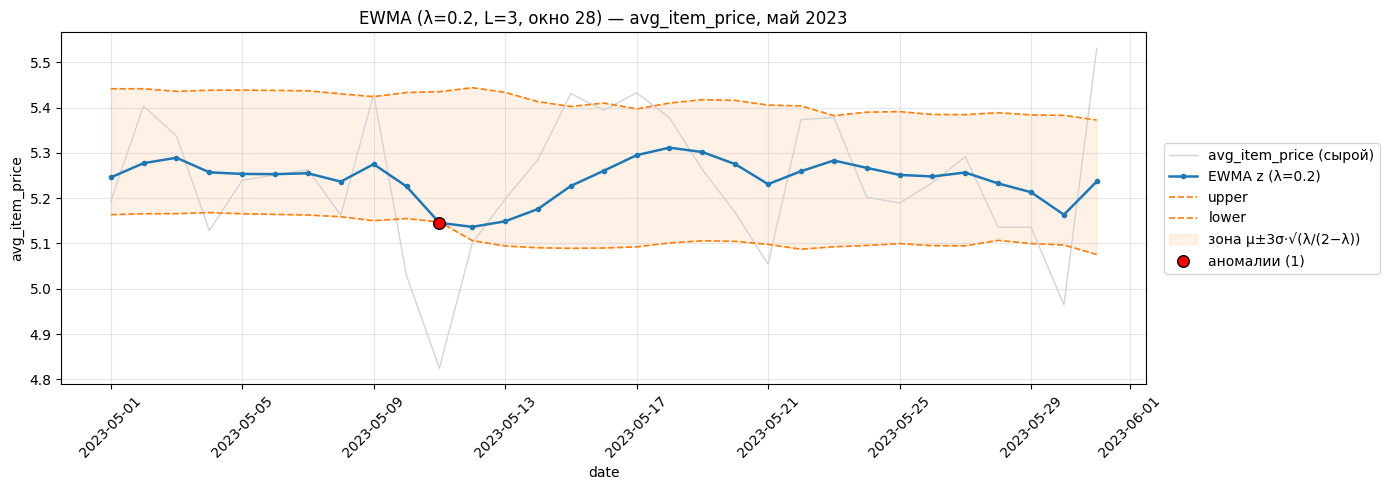

In [ ]:
s_all = df.set_index("date")[["gmv", "items_sold", "avg_item_price"]]
MAY_START, MAY_END = "2023-05-01", "2023-05-31"

ewma_results = {}
for m in ["gmv", "items_sold", "avg_item_price"]:
    r = ewma_control(s_all[m], lam=0.2, L=3.0, window=28)
    ewma_results[m] = r

    d = r.loc[MAY_START:MAY_END]
    print(f"\n=== EWMA: {m} (май 2023) ===")
    print(f"точек: {len(d)}, NaN границ: {d['lower'].isna().sum()}, "
          f"аномалий: {int(d['is_anomaly'].sum())}")
    if d["is_anomaly"].any():
        for dt, row in d[d["is_anomaly"]].iterrows():
            side = "выше" if row["z"] > row["upper"] else "ниже"
            print(f"  {dt.date()}  z={row['z']:.4g}  x={row['x']:.4g}  "
                  f"[{row['lower']:.4g}; {row['upper']:.4g}]  ({side})")

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(d.index, d["x"], color="lightgray", lw=1.0, label=f"{m} (сырой)")

    ax.plot(d.index, d["z"], color="C0", lw=1.8, marker="o", ms=3,
            label="EWMA z (λ=0.2)")

    ax.plot(d.index, d["upper"], "--", color="C1", lw=1.2, label="upper")
    ax.plot(d.index, d["lower"], "--", color="C1", lw=1.2, label="lower")
    ax.fill_between(d.index, d["lower"], d["upper"], color="C1", alpha=0.10,
                    label="зона μ±3σ·√(λ/(2−λ))")

    anom = d[d["is_anomaly"]]
    if len(anom):
        ax.scatter(anom.index, anom["z"], color="red", s=70, zorder=5,
                   edgecolors="black", label=f"аномалии ({len(anom)})")

    ax.set_title(f"EWMA (λ=0.2, L=3, окно 28) — {m}, май 2023")
    ax.set_xlabel("date"); ax.set_ylabel(m)
    ax.grid(alpha=0.3)
    plt.xticks(rotation=45)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()
    plt.show()

Для онлайн-мониторинга больше подходит EWMA из-за адаптации к сдвигу уровня. Если процесс устойчиво сместился (например, вырос трафик после маркетинговой кампании), EWMA «догонит» новый уровень за несколько дней и перестанет генерировать ложные срабатывания. 3σ с окном 28 будет «тормозить»: сдвиг будет раздувать σ и маскировать аномалии, пока окно не перевернётся
Также границы получаются узкими, но при этом корректными: вероятность ложного срабатывания контролируется. Это позволяет ловить малые устойчивые сдвиги, которые 3σ на уровне не видит, к тому же прозрачная интерпретация

Для ретроспективного анализа лучше GESD, тк он работает со множественными выбросами. По итерациям удаляя по одному выбросу и пересчитывая mean/std на оставшихся точках, GESD решает проблему маскировки: когда два выброса «прячут» друг друга, потому что вместе раздувают σ. 3σ в такой ситуации скажет «аномалий нет», GESD найдёт оба
+ можно контролировать аномалии
+ для истории с сезонностью убирает сезонный шум перед детекцией
